In [2]:
import matplotlib.pyplot as plt
import numpy as np
import re
import pandas as pd
from scipy.interpolate import RBFInterpolator
from scipy import optimize
from dolfin import *
import matplotlib as mpl
from scipy.optimize import curve_fit
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
from numpy import inf
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from scipy.optimize import differential_evolution
from sklearn.model_selection import train_test_split
import dill

In [3]:
params = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A']
param_names = ['chem_species.max_seg_length', 'chem_species.seg_split_length',
               'chem_species.max_seg_radius', 'chem_species.splitting_probability',
               'chem_species.fusion_probability', 'chem_species.max_fusion_separation',
               'cell_force.fungi_boundary_width'] 

In [4]:
headers = ['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']
PDE_names = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)['sim_name']
PDE_m = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
m_scaler = MinMaxScaler()
m_scaler.fit(PDE_m)
PDE_m_norm = m_scaler.transform(PDE_m)
PDE_lb = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
lb_scaler = MinMaxScaler()
lb_scaler.fit(PDE_lb)
PDE_lb_norm = lb_scaler.transform(PDE_lb)
PDE_ub = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub.csv', header=None, names=headers)[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
ub_scaler = MinMaxScaler()
ub_scaler.fit(PDE_ub)
PDE_ub_norm = ub_scaler.transform(PDE_ub)

In [5]:
# PDE_names = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean_sorted.csv')['sim_name']
# PDE_m = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean_sorted.csv')[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
# m_scaler = MinMaxScaler()
# m_scaler.fit(PDE_m)
# PDE_m_norm = m_scaler.transform(PDE_m)
# PDE_lb = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_lb_sorted.csv')[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
# lb_scaler = MinMaxScaler()
# lb_scaler.fit(PDE_lb)
# PDE_lb_norm = lb_scaler.transform(PDE_lb)
# PDE_ub = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_ub_sorted.csv')[['alpha', 'beta', 'vd', 'sg', 'D']].to_numpy()
# ub_scaler = MinMaxScaler()
# ub_scaler.fit(PDE_ub)
# PDE_ub_norm = m_scaler.transform(PDE_ub)

In [6]:
def get_n(s):
    match = re.search(r'\d+$', s)
    if match:
        return int(match.group())
    else:
        return None

In [7]:
ABM_256_inputs = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/256_inputs.csv')

In [8]:
ABM_sample = np.zeros((len(PDE_names), 7))
j = 0
# list_n = []
# run_params = {}
sim_names = PDE_names.to_list()
for sim in sim_names:
    n = get_n(sim)
    sim_row = ABM_256_inputs.iloc[n]
    # list_n.append(n)
    # input_filepath = '/Users/laurenyan/bmxfungi_surrogate/256_inputs/input_fungi_' + str(n)
    # params_n = []
    i = 0
    for name in param_names:
        # with open(input_filepath) as input_file:
            # for line in input_file:
                # if line.startswith(name):
                    # ABM_sample[j, i] = re.findall(r"-?\d+\.?\d*(?:[Ee][+-]?\d+)?", line)[0]
        ABM_sample[j, i] = sim_row[name]
                    # params_n.append(re.findall(r"-?\d+\.?\d*(?:[Ee][+-]?\d+)?", line)[0])
        # run_params[n] = params_n
        i += 1
    j += 1

In [9]:
# [[17.5e-4, 52.5e-4], [2.5e-4, 7.5e-4], [1.25e-4, 3.75e-4], [0.1, 0.3], [0.005, 0.015], [3.0e-4, 9.0e-4], [0.5e-4, 1.5e-4]]
ABM_scaler = MinMaxScaler()
ABM_toscale = np.append(ABM_sample, [[16.5e-4, 16.5e-4 - 8.5e-4, 0.25e-4, 0.05, 0.004, 2.0e-4, 0.4e-4]], axis=0) # adding smallest and largest possible values
ABM_toscale = np.append(ABM_toscale, [[53.5e-4, 53.5e-4 - 1.5e-4, 4.75e-4, 0.4, 0.025, 10.0e-4, 1.5e-4]], axis=0)
ABM_scaler.fit(ABM_toscale)
ABM_norm = ABM_scaler.transform(ABM_sample)

In [10]:
def loocv(params, x, y, kernel, rescaler):
    ep, smooth = params
    n = len(x)
    err = []

    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        try:
            rbf = RBFInterpolator(
                x[mask], y[mask],
                kernel=kernel,
                epsilon=ep,
                smoothing=smooth,
            )
            y_hat = rbf(x[i:i+1])[0]
            if rescaler.inverse_transform(y_hat.reshape(1, -1)) < 0:
                err.append(((y_hat - y[i]) ** 2) * 1e10)
            else:
                err.append((y_hat - y[i]) ** 2)
        except (np.linalg.LinAlgError, ValueError):
            return 1e10

    return np.array(err).reshape(-1)

In [11]:
def error_obj(params, x, y, kernel, rescaler):
    loocv_err = loocv(params, x, y, kernel, rescaler)
    test_err = train_test(params, x, y, kernel, rescaler) 
    return np.mean(np.array([np.mean(loocv_err), np.mean(test_err)]))

In [12]:
def train_test(params, x, y, kernel, rescaler):
    ep, smooth = params
    
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)
    
    rbf = RBFInterpolator(x_train, y_train, kernel = kernel, epsilon = ep, smoothing = smooth)
    
    y_hat = rbf(x_test)
    if (rescaler.inverse_transform(y_hat.reshape(1, -1)) < 0).any():
        err = ((y_hat - y_test) ** 2) * 1e10
    else:
        err = (y_hat - y_test) ** 2

    return np.array(err).reshape(-1)

In [13]:
def fit_rbf_param(x, y, rescaler):
    kernels = ['linear', 'gaussian', 'thin_plate_spline', 'multiquadric', 'inverse_multiquadric']
    
    best_overall = None
    
    for kernel in kernels:
        if kernel in {'thin_plate_spline', 'cubic', 'linear', 'quintic'}:
            result = differential_evolution(
                lambda s, X, Y, k, rs: error_obj([1.0, s[0]], X, Y, k, rs),
                bounds = [(1e-5, 10.0)],
                args = (x, y, kernel, rescaler),
                seed = 42,
            )
            score = result.fun
            params = {'kernel': kernel, 'epsilon': 1.0, 'smoothing': result.x[0]}
        else:
            result = differential_evolution(
                error_obj,
                bounds = [(1e-2, 2.0), (1e-5, 10.0)],
                args = (x, y, kernel, rescaler),
                seed = 42,
            )
            score = result.fun
            params = {'kernel': kernel, 'epsilon': result.x[0], 'smoothing': result.x[1]}
    
        print(f"{kernel:>25s} MSE={score:.3e}")
    
        if best_overall is None or score < best_overall['score']:
            best_overall = {'score': score, **params}
    
    print(f"\nBest: {best_overall}")

    return best_overall

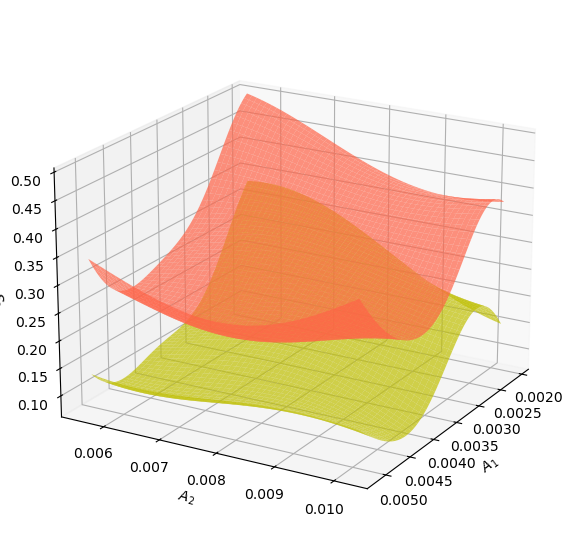

In [184]:
i = 0
j = 4
ABM_2d_norm = np.column_stack((ABM_norm[:, i], ABM_norm[:, j]))
ABM_2d_scaler = MinMaxScaler()
ABM_2d_scaler.fit(np.column_stack((ABM_sample[:, i], ABM_sample[:, j])))
                                  
PDE_alpha = np.column_stack((PDE_m[:, 0], PDE_lb[:, 0], PDE_ub[:, 0]))
alpha_scaler = MinMaxScaler()
alpha_scaler.fit(PDE_alpha)
alpha_norm = alpha_scaler.transform(PDE_alpha)

alpha_m_scaler = MinMaxScaler()
alpha_m_scaler.fit(PDE_alpha[:, 0].reshape(-1,1))
alpha_lb_scaler = MinMaxScaler()
alpha_lb_scaler.fit(PDE_alpha[:, 1].reshape(-1,1))
alpha_ub_scaler = MinMaxScaler()
alpha_ub_scaler.fit(PDE_alpha[:, 2].reshape(-1,1))

kern = 'gaussian'
ep = 2.3
smooth = 0.04

ABM_train, ABM_test, PDE_train, PDE_test = train_test_split(ABM_2d_norm, alpha_norm, test_size=0.33, random_state=42)

rbf_alpha_m_2d = RBFInterpolator(ABM_train, PDE_train[:, 0], kernel = kern, smoothing = smooth, epsilon = ep)
rbf_alpha_lb_2d = RBFInterpolator(ABM_train, PDE_train[:, 1], kernel = kern, smoothing = smooth, epsilon = ep)
rbf_alpha_ub_2d = RBFInterpolator(ABM_train, PDE_train[:, 2], kernel = kern, smoothing = smooth, epsilon = ep)

x_train = ABM_train[:, 0]
x_train_plot = ABM_2d_scaler.inverse_transform(ABM_train)[:, 0]
y_train = ABM_train[:, 1]
y_train_plot = ABM_2d_scaler.inverse_transform(ABM_train)[:, 1]
x_test = ABM_test[:, 0]
x_test_plot = ABM_2d_scaler.inverse_transform(ABM_test)[:, 0]
y_test = ABM_test[:, 1]
y_test_plot = ABM_2d_scaler.inverse_transform(ABM_test)[:, 1]
z_train_plot = alpha_scaler.inverse_transform(PDE_train)[:, 0]
z_test_plot = alpha_scaler.inverse_transform(PDE_test)[:, 0] 

grid_x, grid_y = np.mgrid[x_train.min():x_train.max():200j, y_train.min():y_train.max():200j]
grid_x_plot, grid_y_plot = np.mgrid[x_train_plot.min():x_train_plot.max():200j, y_train_plot.min():y_train_plot.max():200j]

grid_coords = np.vstack((grid_x.ravel(), grid_y.ravel())).T
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')
grid_shape = grid_x.shape

alpha_m_interp_norm = rbf_alpha_m_2d(grid_coords)
alpha_lb_interp_norm = rbf_alpha_lb_2d(grid_coords)
alpha_ub_interp_norm = rbf_alpha_ub_2d(grid_coords)
alpha_interp = alpha_scaler.inverse_transform(np.column_stack((alpha_m_interp_norm.reshape(-1,1), alpha_lb_interp_norm.reshape(-1,1), alpha_ub_interp_norm.reshape(-1,1))))

grid_z_plot = alpha_interp[:, 0].reshape(grid_shape) # Reshape back to the grid structure
ax.plot_surface(grid_x_plot, grid_y_plot, grid_z_plot, alpha=0.7, color = 'tomato', shade=False)

grid_z_plot = alpha_interp[:, 1].reshape(grid_shape) # Reshape back to the grid structure
ax.plot_surface(grid_x_plot, grid_y_plot, grid_z_plot, alpha=0.7, color = 'y', shade = False)

# grid_z_plot = alpha_interp[:, 2].reshape(grid_shape) # Reshape back to the grid structure
# ax.plot_surface(grid_x_plot, grid_y_plot, grid_z_plot, alpha=0.7, color = 'y', shade=False)

ax.view_init(elev=20, azim=30)
# sc1 = ax.scatter(np.concatenate((x_train_plot, x_test_plot), axis=0), np.concatenate((y_train_plot, y_test_plot), axis=0), np.concatenate((z_train_plot, z_test_plot), axis=0), s=50, marker = '.')
ax.set_xlabel(r'$A_{1}$')
ax.set_ylabel(r'$A_{2}$')
ax.set_zlabel(r'$S_{1}$')

plt.savefig('surfaces.svg')

In [232]:
# i = 0
# j = 3
# ABM_2d_norm = np.column_stack((ABM_norm[:, i], ABM_norm[:, j]))
# ABM_2d_scaler = MinMaxScaler()
# ABM_2d_scaler.fit(np.column_stack((ABM_sample[:, i], ABM_sample[:, j])))
                                  
# PDE_alpha = np.column_stack((PDE_m[:, 0], PDE_lb[:, 0], PDE_ub[:, 0]))
# alpha_scaler = MinMaxScaler()
# alpha_scaler.fit(PDE_alpha)
# alpha_norm = alpha_scaler.transform(PDE_alpha)

# alpha_m_scaler = MinMaxScaler()
# alpha_m_scaler.fit(PDE_alpha[:, 0].reshape(-1,1))
# alpha_lb_scaler = MinMaxScaler()
# alpha_lb_scaler.fit(PDE_alpha[:, 1].reshape(-1,1))
# alpha_ub_scaler = MinMaxScaler()
# alpha_ub_scaler.fit(PDE_alpha[:, 2].reshape(-1,1))

# alpha_m_2d_best = fit_rbf_param(ABM_2d_norm, alpha_norm[:, 0], alpha_m_scaler)
# alpha_lb_2d_best = fit_rbf_param(ABM_2d_norm, alpha_norm[:, 1], alpha_lb_scaler)
# alpha_ub_2d_best = fit_rbf_param(ABM_2d_norm, alpha_norm[:, 2], alpha_ub_scaler)

# alpha_m_fit_err = loocv([alpha_m_2d_best['epsilon'], alpha_m_2d_best['smoothing']], ABM_2d_norm, alpha_norm[:, 0], alpha_m_2d_best['kernel'], alpha_m_scaler)
# alpha_m_test_err = train_test([alpha_m_2d_best['epsilon'], alpha_m_2d_best['smoothing']], ABM_2d_norm, alpha_norm[:, 0], alpha_m_2d_best['kernel'], alpha_m_scaler)

In [233]:
# ABM_train, ABM_test, PDE_train, PDE_test = train_test_split(ABM_2d_norm, alpha_norm, test_size=0.33, random_state=42)

# rbf_alpha_m_2d = RBFInterpolator(ABM_train, PDE_train[:, 0], kernel = alpha_m_2d_best['kernel'], smoothing = alpha_m_2d_best['smoothing'], epsilon = alpha_m_2d_best['epsilon'])
# rbf_alpha_lb_2d = RBFInterpolator(ABM_train, PDE_train[:, 1], kernel = alpha_lb_2d_best['kernel'], smoothing = alpha_lb_2d_best['smoothing'], epsilon = alpha_lb_2d_best['epsilon'])
# rbf_alpha_ub_2d = RBFInterpolator(ABM_train, PDE_train[:, 2], kernel = alpha_ub_2d_best['kernel'], smoothing = alpha_ub_2d_best['smoothing'], epsilon = alpha_ub_2d_best['epsilon'])

# x_train = ABM_train[:, 0]
# x_train_plot = ABM_2d_scaler.inverse_transform(ABM_train)[:, 0]
# y_train = ABM_train[:, 1]
# y_train_plot = ABM_2d_scaler.inverse_transform(ABM_train)[:, 1]
# x_test = ABM_test[:, 0]
# x_test_plot = ABM_2d_scaler.inverse_transform(ABM_test)[:, 0]
# y_test = ABM_test[:, 1]
# y_test_plot = ABM_2d_scaler.inverse_transform(ABM_test)[:, 1]
# z_train_plot = alpha_scaler.inverse_transform(PDE_train)[:, 0]
# z_test_plot = alpha_scaler.inverse_transform(PDE_test)[:, 0] 

# grid_x, grid_y = np.mgrid[x_train.min():x_train.max():200j, y_train.min():y_train.max():200j]
# grid_x_plot, grid_y_plot = np.mgrid[x_train_plot.min():x_train_plot.max():200j, y_train_plot.min():y_train_plot.max():200j]

# grid_coords = np.vstack((grid_x.ravel(), grid_y.ravel())).T
# fig = plt.figure(figsize=(10, 8))
# ax = fig.add_subplot(111, projection='3d')
# grid_shape = grid_x.shape

# alpha_m_interp_norm = rbf_alpha_m_2d(grid_coords)
# alpha_lb_interp_norm = rbf_alpha_lb_2d(grid_coords)
# alpha_ub_interp_norm = rbf_alpha_ub_2d(grid_coords)
# alpha_interp = alpha_scaler.inverse_transform(np.column_stack((alpha_m_interp_norm.reshape(-1,1), alpha_lb_interp_norm.reshape(-1,1), alpha_ub_interp_norm.reshape(-1,1))))
# grid_z_plot = alpha_interp[:, 0].reshape(grid_shape) # Reshape back to the grid structure
# ax.plot_surface(grid_x_plot, grid_y_plot, grid_z_plot, cmap='viridis', alpha=0.8)
# grid_z_plot = alpha_interp[:, 1].reshape(grid_shape) # Reshape back to the grid structure
# ax.plot_surface(grid_x_plot, grid_y_plot, grid_z_plot, cmap='plasma', alpha=0.8)
# grid_z_plot = alpha_interp[:, 2].reshape(grid_shape) # Reshape back to the grid structure
# ax.plot_surface(grid_x_plot, grid_y_plot, grid_z_plot, cmap='cividis', alpha=0.8)

# cm1 = plt.get_cmap('YlOrRd')
# cm2 = plt.get_cmap('PuBuGn')
# sc1 = ax.scatter(np.concatenate((x_train_plot, x_test_plot), axis=0), np.concatenate((y_train_plot, y_test_plot), axis=0), np.concatenate((z_train_plot, z_test_plot), axis=0), c = alpha_m_fit_err, s=50, marker = '.', cmap = cm1)
# sc2 = ax.scatter(x_test_plot, y_test_plot, z_test_plot, c = alpha_m_test_err, s=50, marker = '.', cmap = cm2)
# fig.colorbar(sc1, ax=ax)
# fig.colorbar(sc2, ax=ax)
# ax.set_xlabel('X')
# ax.set_ylabel('Y')
# ax.set_zlabel('Z')

# plt.show()

In [ ]:
# fig1, ax1 = plt.subplots(figsize=(8, 5))
# cm1 = plt.get_cmap('YlOrRd')
# cm2 = plt.get_cmap('PuBuGn')
# sc1 = ax1.scatter(np.concatenate((x_train_plot, x_test_plot), axis=0), np.concatenate((y_train_plot, y_test_plot), axis=0), c = alpha_m_fit_err, s=50, marker = '.', cmap = cm1)
# sc2 = ax1.scatter(x_test_plot, y_test_plot, c = alpha_m_test_err, s=50, marker = '*', cmap = cm2)
# fig1.colorbar(sc1, ax=ax1, label = 'fit data (.)')
# fig1.colorbar(sc2, ax=ax1, label = 'test data (*)')
# ax1.set_xlabel('X')
# ax1.set_ylabel('Y')

                   linear MSE=3.954e-02
                 gaussian MSE=3.897e-02
        thin_plate_spline MSE=5.644e+04
             multiquadric MSE=3.908e-02
     inverse_multiquadric MSE=3.901e-02

Best: {'score': np.float64(0.03897105087981971), 'kernel': 'gaussian', 'epsilon': np.float64(0.5721300244546799), 'smoothing': np.float64(0.5090447444684197)}
                   linear MSE=3.047e-02
                 gaussian MSE=3.058e-02
        thin_plate_spline MSE=1.764e+08
             multiquadric MSE=3.058e-02
     inverse_multiquadric MSE=3.058e-02

Best: {'score': np.float64(0.030467909231102493), 'kernel': 'linear', 'epsilon': 1.0, 'smoothing': np.float64(2.8215601887513864)}
                   linear MSE=2.827e-02
                 gaussian MSE=2.806e-02
        thin_plate_spline MSE=1.601e+08
             multiquadric MSE=2.806e-02
     inverse_multiquadric MSE=2.807e-02

Best: {'score': np.float64(0.028057015173853405), 'kernel': 'multiquadric', 'epsilon': np.float64(0.9246721

KeyboardInterrupt: 

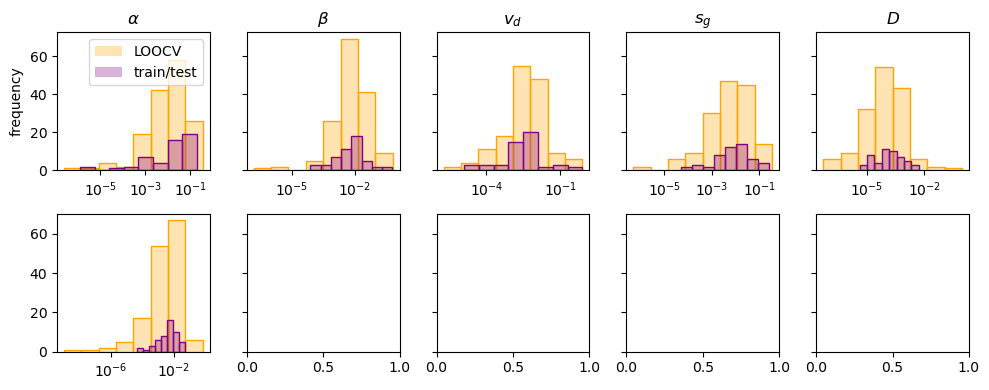

In [31]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4), sharey='row', tight_layout=True)
PDE_par = [r'$\alpha$', r'$\beta$', r'$v_d$', r'$s_g$', r'$D$']
bns = 8
ts = 0.33
a = 0.3
err_m = []
err_lb = []
err_ub = []

# # median/mean
# for i in range(5):
#     print('interpolating ' + str(PDE_par[i]) + ' mean.')
#     scaler = MinMaxScaler()
#     scaler.fit(PDE_m[:, i].reshape(-1,1))
#     PDE_norm = scaler.transform(PDE_m[:, i].reshape(-1,1))
#     rbf_fit = fit_rbf_param(ABM_norm, PDE_norm, scaler)
#     kern = rbf_fit['kernel']
#     smooth = rbf_fit['smoothing']
#     ep = rbf_fit['epsilon']
#     train_err = loocv([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
#     test_err = train_test([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
#     err_mask = train_err > 10
#     if len(ABM_sample[err_mask]) > 0:
#         err_m.append(ABM_sample[err_mask])
    
#     logbins = np.geomspace(min(train_err), max(train_err), bns+1)
#     ax[0,i].hist(train_err, label = 'training data', bins=logbins, alpha=a)
#     logbins = np.geomspace(min(test_err), max(test_err), bns+1)
#     ax[0,i].hist(test_err, label = 'test data', bins=logbins, alpha=a)
#     ax[0,i].set_title(PDE_par[i] + ' mean')
#     ax[0,i].set_xscale('log')
#     ax[0,i].legend()
          
#     rbfi = RBFInterpolator(ABM_norm, PDE_norm, kernel = kern, epsilon = ep, smoothing = smooth)
#     with open(PDE_par[i] + '_mn_rbf' + '.pkl', 'wb') as f:
#         dill.dump(rbfi, f)
    
# lower bound
for i in range(5):
    # print('interpolating ' + str(PDE_par[i]) + ' lower.')
    scaler = MinMaxScaler()
    scaler.fit(PDE_lb[:, i].reshape(-1,1))
    PDE_norm = scaler.transform(PDE_lb[:, i].reshape(-1,1))
    rbf_fit = fit_rbf_param(ABM_norm, PDE_norm, scaler)
    kern = rbf_fit['kernel']
    smooth = rbf_fit['smoothing']
    ep = rbf_fit['epsilon']
    train_err = loocv([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    test_err = train_test([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    err_mask = train_err > 10
    if len(ABM_sample[err_mask]) > 0:
        err_lb.append(ABM_sample[err_mask])
    
    logbins = np.geomspace(min(train_err), max(train_err), bns+1)
    ax[0,i].hist(train_err, label = 'LOOCV', bins=logbins, facecolor = 'orange', alpha=a)
    ax[0,i].hist(train_err, bins=logbins, facecolor = 'None', edgecolor = 'orange', alpha=1)
    logbins = np.geomspace(min(test_err), max(test_err), bns+1)
    ax[0,i].hist(test_err, label = 'train/test', bins=logbins, facecolor = 'purple', alpha=a)
    ax[0,i].hist(test_err, bins=logbins, facecolor = 'None', edgecolor = 'purple', alpha=1)
    ax[0,i].set_title(PDE_par[i])
    ax[0,i].set_xscale('log')
ax[0,0].legend()
ax[0,0].set_ylabel('frequency')
    # rbfi = RBFInterpolator(ABM_norm, PDE_norm, kernel = kern, smoothing = smooth, epsilon = ep)
    # with open(PDE_par[i] + '_lb_rbf' + '.pkl', 'wb') as f:
    #     dill.dump(rbfi, f)
        
# upper bound
for i in range(5):
    # print('interpolating ' + str(PDE_par[i]) + ' upper.')
    scaler = MinMaxScaler()
    scaler.fit(PDE_ub[:, i].reshape(-1,1))
    PDE_norm = scaler.transform(PDE_ub[:, i].reshape(-1,1))
    rbf_fit = fit_rbf_param(ABM_norm, PDE_norm, scaler)
    kern = rbf_fit['kernel']
    smooth = rbf_fit['smoothing']
    ep = rbf_fit['epsilon']
    train_err = loocv([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    test_err = train_test([ep, smooth], ABM_norm, PDE_norm, kern, scaler)
    err_mask = train_err > 10
    if len(ABM_sample[err_mask]) > 0:
        err_ub.append(ABM_sample[err_mask])
    
    logbins = np.geomspace(min(train_err), max(train_err), bns+1)
    ax[1,i].hist(train_err, label = 'LOOCV', bins=logbins, facecolor = 'orange', alpha=a)
    ax[1,i].hist(train_err, bins=logbins, facecolor = 'None', edgecolor = 'orange', alpha=1)
    logbins = np.geomspace(min(test_err), max(test_err), bns+1)
    ax[1,i].hist(test_err, label = 'train/test', bins=logbins, facecolor = 'purple', alpha=a)
    ax[1,i].hist(test_err, bins=logbins, facecolor = 'None', edgecolor = 'purple', alpha=1)
    # ax[1,i].set_title(PDE_par[i] + ' upper surface')
    ax[1,i].set_xscale('log')
# ax[1,0].legend()
ax[1,0].set_ylabel('frequency')

    # rbfi = RBFInterpolator(ABM_norm, PDE_norm, kernel = kern, smoothing = smooth, epsilon = ep)
    # with open(PDE_par[i] + '_ub_rbf' + '.pkl', 'wb') as f:
    #     dill.dump(rbfi, f)
fig.supxlabel('RSS')
plt.savefig('interp_err.svg')
# err_mn = np.concatenate(err_m, axis=0)
# err_lb = np.concatenate(err_lb, axis=0)
# err_ub = np.concatenate(err_ub, axis=0)

In [487]:
from SALib.sample import latin
from SALib.sample import saltelli
# SA_in = {
#     'num_vars': 7,
#     'names': ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A'],
#     'bounds': [[17.5e-4, 52.5e-4], [2.5e-4, 7.5e-4], [1.25e-4, 3.75e-4], [0.1, 0.3], [0.005, 0.015], [3.0e-4, 9.0e-4], [0.5e-4, 1.5e-4]]
# }
SA_in = {
    'num_vars': 7,
    'names': ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A'],
    'bounds': [[np.min(ABM_sample[:, 0]), np.max(ABM_sample[:, 0])],
               [np.min(ABM_sample[:, 0] - ABM_sample[:, 1]), np.max(ABM_sample[:, 0] - ABM_sample[:, 1])],
               [np.min(ABM_sample[:, 2]), np.max(ABM_sample[:, 2])],
               [np.min(ABM_sample[:, 3]), np.max(ABM_sample[:, 3])],
               [np.min(ABM_sample[:, 4]), np.max(ABM_sample[:, 4])],
               [np.min(ABM_sample[:, 5]), np.max(ABM_sample[:, 5])],
               [np.min(ABM_sample[:, 6]), np.max(ABM_sample[:, 6])]]
}
ABM_in = latin.sample(SA_in, 2000)
ABM_in[:, 1] = ABM_in[:, 0] - ABM_in[:, 1] # split length is sampled as the difference between split length and maximum length
ABM_in_norm = ABM_scaler.transform(ABM_in)

In [488]:
name = 'D'
i = 1
# '/Users/laurenyan/bmxfungi_surrogate/rbf_pickles/' + 
with open(name + '_ub_rbf.pkl', 'rb') as f:
    rbfcheck = dill.load(f)
scaler = MinMaxScaler(feature_range=(0, 100))
scaler.fit(PDE_ub[:, i].reshape(-1,1))
ycheck_norm = rbfcheck(ABM_in_norm)
ycheck = scaler.inverse_transform(ycheck_norm)
# print(PDE_norm)
# print(scaler.inverse_transform(PDE_norm)) 
print(ycheck[ycheck<0])

[]


In [43]:
# # if the interpolator is dilled in another file, it can be called here and used
# with open('/Users/laurenyan/bmxfungi_surrogate/rbf_interpolator.pkl', 'rb') as f:
#     rbf_interpolator_loaded = dill.load(f)

In [44]:
# num_points = 50
# x = np.random.rand(num_points) * 10
# y = np.random.rand(num_points) * 10
# z = np.random.rand(num_points) * 10

# grid_x, grid_y = np.mgrid[x.min():x.max():200j, y.min():y.max():200j]

# grid_coords = np.vstack((grid_x.ravel(), grid_y.ravel())).T
# grid_z = rbf_interpolator_loaded(grid_coords)
# grid_z = grid_z.reshape(grid_x.shape) # Reshape back to the grid structure

# fig = plt.figure(figsize=(10, 8))
# ax = fig.add_subplot(111, projection='3d')
# ax.plot_surface(grid_x, grid_y, grid_z, cmap='viridis', alpha=0.8)

# ax.contour(grid_x, grid_y, grid_z, zdir='z', offset=-1, cmap='coolwarm')
# ax.contour(grid_x, grid_y, grid_z, zdir='x', offset=-1, cmap='coolwarm')
# ax.contour(grid_x, grid_y, grid_z, zdir='y', offset=10, cmap='coolwarm')

# ax.scatter(0.08280326, 0.26359223, rbf_interpolator_loaded([[0.08280326, 0.26359223]]), color = 'r')
# ax.scatter(6, 6, rbf_interpolator_loaded([[6, 6]]), color ='r')
# ax.scatter(2, 2, rbf_interpolator_loaded([[2, 2]]), color ='r')


# ax.set_xlabel('X')
# ax.set_ylabel('Y')
# ax.set_zlabel('Z')
# ax.legend()

# plt.show()

In [ ]:
# manually constraining non-negative interpolation

In [45]:
from sklearn.metrics.pairwise import rbf_kernel

In [46]:
rbf_kernel(ABM_2d)

array([[1.        , 0.99994904, 0.9959581 , ..., 0.99595808, 0.99954975,
        0.99820078],
       [0.99994904, 1.        , 0.99680467, ..., 0.99501207, 0.99920017,
        0.997553  ],
       [0.9959581 , 0.99680467, 1.        , ..., 0.98393051, 0.99282578,
        0.98881268],
       ...,
       [0.99595808, 0.99501207, 0.98393051, ..., 1.        , 0.99820155,
        0.99954977],
       [0.99954975, 0.99920017, 0.99282578, ..., 0.99820155, 1.        ,
        0.99955   ],
       [0.99820078, 0.997553  , 0.98881268, ..., 0.99954977, 0.99955   ,
        1.        ]], shape=(59, 59))

In [47]:
def phi(r):
    phi = np.exp(-(3 * r) ** 2)
    return phi

In [48]:
def distance(x1, x2):
    sum = 0
    for i in range(len(x1)):
        sum += (x2[i] - x1[i]) ** 2

    return np.sqrt(sum)

In [49]:
def f_interpolate(x, xk, k, omega):
    '''
    x = the point to interpolate for
    xk = sample points being interpolated over
    k = number of sample points
    omega = weight for each sample point
    '''
    s = 0
    for i in range(k + 1):
        s += omega[i] * phi(distance(x - xk[i]))

    return s

In [50]:
k = len(PDE_med)
A = np.zeros((k,k))

In [51]:
xk = ABM_2d
for i in range(k):
    for j in range(k):
        A[i,j] = phi(distance(xk[i], xk[j]))

In [52]:
A

array([[1.        , 0.99908321, 0.9296922 , ..., 0.92969187, 0.99192642,
        0.96810462],
       [0.99908321, 1.        , 0.94401986, ..., 0.91392446, 0.98570057,
        0.9568582 ],
       [0.9296922 , 0.94401986, 1.        , ..., 0.74706729, 0.87844545,
        0.81668105],
       ...,
       [0.92969187, 0.91392446, 0.74706729, ..., 1.        , 0.96811812,
        0.99192676],
       [0.99192642, 0.98570057, 0.87844545, ..., 0.96811812, 1.        ,
        0.99193086],
       [0.96810462, 0.9568582 , 0.81668105, ..., 0.99192676, 0.99193086,
        1.        ]], shape=(59, 59))

In [66]:
omega = nnls(A, PDE_beta_m)

In [67]:
PDE_beta_m

array([0.0070596 , 0.00090383, 0.01344096, 0.05484656, 0.04519029,
       0.00097185, 0.00063874, 0.03385191, 0.01578817, 0.00406078,
       0.00339078, 0.00357505, 0.00122445, 0.02261819, 0.00474323,
       0.02021097, 0.01181502, 0.00863193, 0.02499009, 0.00041628,
       0.02770823, 0.03559808, 0.01053435, 0.01768889, 0.01165341,
       0.00620952, 0.00783403, 0.00450469, 0.01281084, 0.00680824,
       0.02114198, 0.00158053, 0.0121264 , 0.033581  , 0.00146125,
       0.0241957 , 0.00849465, 0.00100676, 0.0115442 , 0.00660354,
       0.03646527, 0.00787767, 0.00746946, 0.00507863, 0.01237671,
       0.00880289, 0.00541623, 0.02149465, 0.00082345, 0.01209876,
       0.01489894, 0.0142406 , 0.0143475 , 0.0075151 , 0.00553781,
       0.00722723, 0.00862292, 0.03392699, 0.00841918])